# 03b — Physical projections starting from 03 warmup results

Load the **complex Fourier-space `warmup_fields` saved by 03** and continue with the joint physical model used by 02. No warmup, random initialization, recropping, rebinning, new PNG masks, support morphology, or Poisson refinement is run. The saved measurements and detector exclusions are reused. The modal geometry is checked against the saved supports before retrieval.

**Run from the top:** choose a 03 run and optional point subset, inspect inputs, edit the complete recipe below, then run the projection/retrieval cell. Each outer round performs the listed phase-retrieval stages for the selected states, followed by a joint physical projection. Defaults follow 02: four rounds, ER 100 + ER 100, physical relaxation 0.2, three physical-fit iterations, fixed binary material thickness, saturated primary field frozen, and higher modes constrained to be common across states. Only the primary mode enters the physical charge/magnetization model.

This notebook keeps all selected states in memory because the physical fit couples them. Start with a subset if needed; the loading cell prints the input-array memory estimate. It consumes completed per-state files from one 03 run, including its saturated reference. A run still in progress contributes only files already listed in its saved summary when this notebook loads it.

The **recipe is explicit and editable here**, not imported from 01/02/03. Source metadata supplies geometry, mode factors, energy and provenance. This workflow currently expects coherent 03 warmups; saved partial-coherence fields without their kernels cannot be resumed faithfully.

Every physical round saves a diagnostic figure and metrics; full intermediate checkpoints are optional. Final HDF5 stores initial/final complex fields, measurements, masks, all modal supports, physical components, errors, source paths and the recipe. Per-state detector/real-space diagnostics and native-resolution complex reconstructions/difference ROIs are also saved in a new `physical_from_03/<timestamp>/` directory. The source 03 run is never overwritten.

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import sys, json, csv
import h5py
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

HERE = Path.cwd()
if not (HERE / "result_io.py").is_file():
    HERE = HERE / "aperiodic_ajajas"
HERE = HERE.resolve()
sys.path.insert(0, str(HERE.parent))
from library import phase_retrieval_universal as universal
from library import phase_retrieval_core_unified as unified
from library import phase_retrieval_geometry as geometry
from library import poisson_refinement as poisson
from library import fthcore as fth
from library.retrieval_progress import retrieval_progress
from aperiodic_ajajas.result_io import result_catalog

# Select inputs. None selects the latest run containing a saved saturated reference.
SATURATED_SCAN = 2923
LOOP_SCAN = 2924
SOURCE_RUN = None  # Or Path("/absolute/path/to/scans_2923_2924/sequential/<timestamp>")
POINT_NUMBERS = None  # None = all saved loop points; e.g. [0, 10, 25, 55].
STATE_STRIDE = 7  # Applies only when POINT_NUMBERS is None; saturation is always included.
MAX_LOOP_STATES = None  # Optional cap after selection, e.g. 8.
OUTPUT_ROOT = HERE / "processed" / f"scans_{SATURATED_SCAN}_{LOOP_SCAN}" / "physical_from_03"

# Physical model and displays. These are editable independently of 02.
SATURATED_SIGN = +1
FREEZE_SATURATED_FIELD = True
CONSTRAIN_OTHER_MODES_COMMON = True
THICKNESS_APERTURE_MODE = "fixed"  # "fixed" binary material aperture, or "fit" relative thickness.
DISPLAY_PROP_UM = 2.05
DISPLAY_PHASE_RAD = -0.76
DISPLAY_SETUP_BASE = {"ccd_dist": 0.125, "px_size": 11e-6}
DIAGNOSTIC_POINT_NUMBER = None  # None chooses the first selected loop point.
DIAGNOSTIC_ROI = None  # None uses the primary support's object aperture; or np.s_[r0:r1, c0:c1].
SHOW_EVERY = 10
SHOW_ROUND_DIAGNOSTICS = True
SAVE_ROUND_FIELDS = False  # Full-stack checkpoints can be several GiB per round.
SAVE_NATIVE_PNGS = True


## Select the saved 03 states and inspect metadata

The point numbers are acquisition numbers, not array positions. Selection retains source-run order; the saturated reference is always first. No large field stack is loaded in this cell.

In [3]:
if SOURCE_RUN is None:
    candidates = sorted((HERE / "processed" / f"scans_{SATURATED_SCAN}_{LOOP_SCAN}" / "sequential").glob("*"))
    candidates = [path for path in candidates if (path / "saturated" / "result.h5").is_file()]
    if not candidates:
        raise FileNotFoundError("No 03 saturated result found for this scan pair; set SOURCE_RUN explicitly")
    SOURCE_RUN = candidates[-1]
SOURCE_RUN = Path(SOURCE_RUN).expanduser().resolve()
records = result_catalog(SOURCE_RUN)
saturated_records = [row for row in records if row["point_number"] < 0]
if len(saturated_records) != 1:
    raise ValueError("Select one 03 run with exactly one saved saturated reference")
loop_records = [row for row in records if row["point_number"] >= 0]
available_points = [row["point_number"] for row in loop_records]
if len(set(available_points)) != len(available_points):
    raise ValueError("Duplicate acquisition numbers in source run")
if POINT_NUMBERS is not None:
    if (not POINT_NUMBERS or len(set(POINT_NUMBERS)) != len(POINT_NUMBERS)
            or any(type(point) is not int or point < 0 for point in POINT_NUMBERS)):
        raise ValueError("POINT_NUMBERS must contain unique nonnegative acquisition numbers")
    missing = set(POINT_NUMBERS) - set(available_points)
    if missing:
        raise ValueError(f"Requested points are not saved yet: {sorted(missing)}")
    loop_records = [row for row in loop_records if row["point_number"] in POINT_NUMBERS]
else:
    if type(STATE_STRIDE) is not int or STATE_STRIDE < 1:
        raise ValueError("STATE_STRIDE must be a positive integer")
    loop_records = loop_records[::STATE_STRIDE]
if MAX_LOOP_STATES is not None:
    if type(MAX_LOOP_STATES) is not int or MAX_LOOP_STATES < 1:
        raise ValueError("MAX_LOOP_STATES must be a positive integer or None")
    loop_records = loop_records[:MAX_LOOP_STATES]
if not loop_records:
    raise ValueError("Select at least one saved loop state")
selected_records = saturated_records + loop_records
source_paths = [row["path"] for row in selected_records]
state_labels = ["saturated"] + [f"loop_{row['point_number']:04d}" for row in loop_records]
point_numbers = np.array([row["point_number"] for row in selected_records], dtype=int)
currents = np.array([row["current_A"] for row in selected_records], dtype=float)
if DIAGNOSTIC_POINT_NUMBER is None:
    diagnostic_observation = 1
else:
    if DIAGNOSTIC_POINT_NUMBER not in point_numbers[1:]:
        raise ValueError("DIAGNOSTIC_POINT_NUMBER must be a selected loop point")
    diagnostic_observation = list(point_numbers).index(DIAGNOSTIC_POINT_NUMBER)

with h5py.File(source_paths[0], "r") as h:
    source_settings = json.loads(h.attrs.get("settings_json", "{}"))
    source_recipe = json.loads(h.attrs.get("recipe_json", "{}"))
    source_shape = h["warmup_fields"].shape
    if len(source_shape) != 3:
        raise ValueError("Expected 03 warmup_fields shaped (modes, rows, columns)")
    nmodes, ny, nx = source_shape
    MODES = source_recipe.get("modes") or source_settings.get("MODES")
    if MODES is None or len(MODES) != nmodes or MODES[0] != 1:
        raise ValueError("Saved mode factors are missing or inconsistent")
    MODE_SUPPORT_CENTER = source_recipe.get("mode_support_center", source_settings.get("MODE_SUPPORT_CENTER"))
    if MODE_SUPPORT_CENTER not in {"image", "components"}:
        raise ValueError("Saved support expansion convention is missing")
    ENERGY_EV = float(h.attrs["energy_eV"])
    saved_modal_supports = h["modal_supports"][()]
    source_scan_pair = (int(h.attrs["saturated_scan"]), int(h.attrs["loop_scan"]))
    if source_scan_pair != (SATURATED_SCAN, LOOP_SCAN):
        raise ValueError(f"Source scan pair is {source_scan_pair}; correct the scan settings")
    if source_settings.get("USE_PARTIAL_COHERENCE", False) or any(source_recipe.get("RL_its", [])):
        raise ValueError("This continuation expects coherent 03 warmups; partial-coherence kernels are not stored by 03")
if saved_modal_supports.shape != source_shape or not np.isin(saved_modal_supports, [0, 1]).all():
    raise ValueError("Saved modal supports must be binary and match the field grid")
support_used = saved_modal_supports[0].copy()
# The existing solver constructs modal supports from the primary support. Prove
# that this is exactly the already-saved geometry before passing any fields.
expected_modal_supports, expected_modal_shifts = geometry.recenter_modal_supports(
    support_used, MODES, center=MODE_SUPPORT_CENTER,
)
if not np.array_equal(expected_modal_supports, saved_modal_supports):
    raise ValueError("Saved modal supports cannot be reproduced exactly; refusing to change their geometry")
DISPLAY_SETUP = {**DISPLAY_SETUP_BASE, "energy": ENERGY_EV}
if DIAGNOSTIC_ROI is None:
    DIAGNOSTIC_ROI = geometry.support_bounding_roi(support_used, 0.15)
if (not isinstance(DIAGNOSTIC_ROI, tuple) or len(DIAGNOSTIC_ROI) != 2
        or any(not isinstance(part, slice) or part.step not in (None, 1)
               or (part.start is not None and not 0 <= part.start < size)
               or (part.stop is not None and not 0 < part.stop <= size)
               for part, size in zip(DIAGNOSTIC_ROI, (ny, nx)))
        or not support_used[DIAGNOSTIC_ROI].size):
    raise ValueError("DIAGNOSTIC_ROI must be a nonempty in-bounds pair of slices")
input_bytes = len(source_paths) * ny * nx * (16 * nmodes + 8 + 2)
print("Source run:", SOURCE_RUN)
print("Selected acquisition points:", point_numbers.tolist())
print("Energy:", ENERGY_EV, "eV; field grid:", source_shape, "mode factors:", MODES)
print("Saved modal geometry:", MODE_SUPPORT_CENTER, "; shifts:", expected_modal_shifts)
print(f"Input arrays: approximately {input_bytes / 2**30:.2f} GiB. Solver copies and physical-fit arrays need additional memory.")


Source run: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/processed/scans_2923_2924/sequential/20261001_102041_895666
Selected acquisition points: [-1, 0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100]
Energy: 783.0104968 eV; field grid: (2, 1048, 1048) mode factors: [1, 2]
Saved modal geometry: image ; shifts: [(0, 0), (64, 0)]
Input arrays: approximately 0.95 GiB. Solver copies and physical-fit arrays need additional memory.


## Load exactly the saved warmup fields, measurements and masks

`start_fields` is a direct copy of 03's `warmup_fields`, never its Poisson output or real-space reconstruction. Supports and metadata must agree across all selected files. No input intensity normalization or geometry transformation is applied.

Loaded 1/22: saturated
Loaded 2/22: loop_0000
Loaded 3/22: loop_0005
Loaded 4/22: loop_0010
Loaded 5/22: loop_0015
Loaded 6/22: loop_0020
Loaded 7/22: loop_0025
Loaded 8/22: loop_0030
Loaded 9/22: loop_0035
Loaded 10/22: loop_0040
Loaded 11/22: loop_0045
Loaded 12/22: loop_0050
Loaded 13/22: loop_0055
Loaded 14/22: loop_0060
Loaded 15/22: loop_0065
Loaded 16/22: loop_0070
Loaded 17/22: loop_0075
Loaded 18/22: loop_0080
Loaded 19/22: loop_0085
Loaded 20/22: loop_0090
Loaded 21/22: loop_0095
Loaded 22/22: loop_0100
Loaded warmup stack: (22, 2, 1048, 1048)


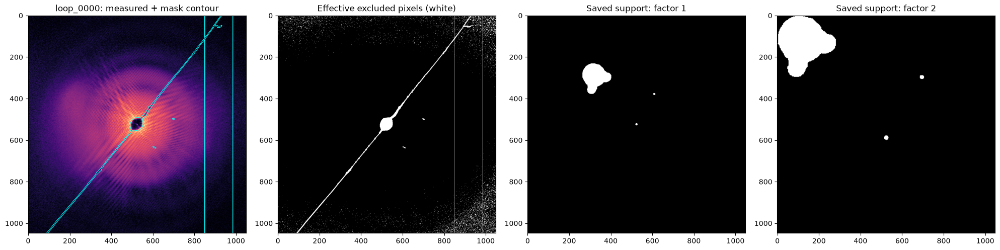

In [4]:
start_modes = np.empty((len(source_paths), nmodes, ny, nx), dtype=np.complex128)
holograms = np.empty((len(source_paths), ny, nx), dtype=np.float64)
mask_pixel = np.empty(holograms.shape, dtype=np.uint8)
effective_source_masks = np.empty_like(mask_pixel)
source_metadata = []
for observation, path in enumerate(source_paths):
    with h5py.File(path, "r") as h:
        if h.attrs.get("field_domain") != "centered Fourier":
            raise ValueError(f"{path}: expected centered Fourier fields")
        if (int(h.attrs["saturated_scan"]), int(h.attrs["loop_scan"])) != source_scan_pair:
            raise ValueError(f"{path}: scan pair differs from saturation")
        if not np.isclose(float(h.attrs["energy_eV"]), ENERGY_EV, rtol=0, atol=1e-6):
            raise ValueError(f"{path}: energy differs from saturation")
        if h["warmup_fields"].shape != source_shape or h["measured"].shape != (ny, nx):
            raise ValueError(f"{path}: field or measurement shape differs")
        if not np.array_equal(h["modal_supports"][()], saved_modal_supports):
            raise ValueError(f"{path}: modal supports differ from saturation")
        local_mask = h["mask"][()]
        if local_mask.shape != (ny, nx) or not np.isin(local_mask, [0, 1]).all():
            raise ValueError(f"{path}: detector mask is not binary/on the saved grid")
        start_modes[observation] = h["warmup_fields"][()]
        holograms[observation] = h["measured"][()]
        mask_pixel[observation] = local_mask
        effective = (h["effective_mask"][()] if "effective_mask" in h else
                     ((local_mask != 0) | ~np.isfinite(holograms[observation])
                      | (holograms[observation] <= 0)))
        if (effective.shape != (ny, nx) or not np.isin(effective, [0, 1]).all()
                or np.any((local_mask != 0) & (effective == 0))):
            raise ValueError(f"{path}: invalid effective detector exclusions")
        effective_source_masks[observation] = effective
        if not np.isfinite(start_modes[observation]).all():
            raise ValueError(f"{path}: nonfinite starting field")
        if not np.isfinite(holograms[observation]).all():
            raise ValueError(f"{path}: nonfinite measurements; repair the source result first")
        if not np.any((effective == 0) & (holograms[observation] > 0)):
            raise ValueError(f"{path}: no positive unmasked measurements")
        source_metadata.append({key: value for key, value in h.attrs.items()})
    print(f"Loaded {observation + 1}/{len(source_paths)}: {state_labels[observation]}", flush=True)
# Universal driver uses (observations, rows, columns) for a single mode.
start_fields = start_modes if nmodes > 1 else start_modes[:, 0]
print("Loaded warmup stack:", start_fields.shape)
fig, axes = plt.subplots(1, 2 + nmodes, figsize=(5 * (2 + nmodes), 5))
obs = diagnostic_observation
axes[0].imshow(np.log1p(np.maximum(holograms[obs], 0)), cmap="magma", origin="upper")
if mask_pixel[obs].any():
    axes[0].contour(mask_pixel[obs], levels=[0.5], colors="cyan", linewidths=0.7)
axes[0].set_title(f"{state_labels[obs]}: measured + mask contour")
axes[1].imshow(effective_source_masks[obs], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Effective excluded pixels (white)")
for mode, ax in enumerate(axes[2:]):
    ax.imshow(saved_modal_supports[mode], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Saved support: factor {MODES[mode]}")
plt.tight_layout()
plt.show()


## Editable physical-projection and phase-retrieval recipe

The saved fields are the starting point: `warmup_Nit=0` and both role-specific warmup schedules are disabled. Keep `crop=0`, `binning=1`: these inputs already occupy the final retrieval grid. The original modal geometry is verified rather than silently changed.

As in 02, the largest primary-support aperture defines material; reference holes are vacuum for the thickness model. Higher modes can be projected to one common field across states. With that option enabled, freezing saturation freezes its **primary mode**; its higher modes still participate in the common-mode projection. `final_projection_relaxation=0` skips an extra final physical projection. Returned components describe the last physical fit, not a new fit to the final Fourier-constrained fields.

In [5]:
if THICKNESS_APERTURE_MODE not in {"fixed", "fit"}:
    raise ValueError("THICKNESS_APERTURE_MODE must be fixed or fit")
material_aperture = universal.largest_support_component(support_used).astype(bool)
recipe = universal.default_universal_phase_retrieval_recipe()
recipe.update(
    # Saved 03 fields are passed through start_fields; no warmup is executed.
    warmup_mode="ER", warmup_Nit=0,
    warmup_reference_mode=None, warmup_reference_Nit=None,
    warmup_other_mode=None, warmup_other_Nit=None,
    warmup_start_from_first=False,
    preserve_warmup_masked_intensity=False,
    startimage_radial_normalization=False,
    # Preserve source geometry and support-factor labels.
    modes=MODES, mode_support_center=MODE_SUPPORT_CENTER,
    recenter_modal_supports=True,
    crop=0, binning=1, roi=None,
    hologram_intensity_cutoff_vmin=-1,
    # Detector/support updates for each state, followed by one physical fit.
    inner_mode=["ER", "ER"], inner_Nit=[100, 100],
    outer_iterations=4,
    beta_zero=0.5, beta_mode="const",
    alpha_zero=0.4, alpha_mode="linear_to_0", TV_freq=5,
    average_img=10, Fourier_last=True, plot_every=10**9,
    shuffle_observations=True, random_seed=0,
    observation_workers=1, fft_workers=1,
    # Coherent continuation; there is no additional Poisson polishing.
    partial_coherence=False, RL_it=0, RL_freq=10**9,
    coherent_refresh_rounds=[],
    # Physical model settings initialized from notebook 02.
    projection_model="physical_factorized",
    projection_every=len(state_labels), projection_start=None,
    projection_relaxation=0.2,
    physical_iterations=3,
    final_projection_relaxation=0.0,
    final_fourier_constraint=True,
    physical_projection_object_roi=True,
    physical_phase_reference=True,
    projection_constraints_inside_support_only=True,
    zero_magnetization_outside_support=True,
    material_mask=(material_aperture if THICKNESS_APERTURE_MODE == "fit" else None),
    material_thickness=(material_aperture.astype(float) if THICKNESS_APERTURE_MODE == "fixed" else None),
    fit_material_thickness=(THICKNESS_APERTURE_MODE == "fit"),
    zero_thickness_outside_support=False,
    saturated_states={"saturated": SATURATED_SIGN},
    freeze_saturated_fields=FREEZE_SATURATED_FIELD,
    constrain_nonphysical_modes_common=CONSTRAIN_OTHER_MODES_COMMON,
    nonphysical_modes_common_relaxation=1.0,
    energy_values=np.array([ENERGY_EV]),
    projection_focus_prop_um=DISPLAY_PROP_UM,
    projection_focus_phase_rad=DISPLAY_PHASE_RAD,
    projection_focus_setup=DISPLAY_SETUP,
    projection_diagnostic_observation=diagnostic_observation,
)
universal.print_universal_workflow(recipe, state_labels=state_labels)
plt.show()


Universal phase-retrieval workflow
├─ Geometry: crop 0 pixels, then bin ×1
├─ Reference hologram: 'saturated'
│  ├─ start: measured amplitude with seeded random phase in each mode
│  └─ warmup disabled
├─ Other holograms: 21 observations ('loop_0000' … 'loop_0100')
│  ├─ start: measured amplitude with seeded random phase in each mode
│  └─ warmup disabled
├─ Joint reconstruction × 4 outer loops
│  ├─ observation order: shuffled each loop
│  ├─ each hologram: ER × 100, support weight 0.4 (linear_to_0), TV every 5
│  ├─ each hologram: ER × 100, support weight 0.4 (linear_to_0), TV every 5
│  └─ physical_factorized projection every 22 observation updates; relaxation=0.2
│     focus before projection: 2.05 µm, phase -0.76 rad; reverse afterward
├─ Modes: [1, 2]; physical constraints act on support-factor-1 mode
├─ Other modes: state-independent common object per energy/beam; relaxation=1.0
├─ CPU workers: 1; FFT threads each: 1
├─ Saturated observations remain fixed after warmup
├─ Final p

## Output directory and diagnostic helpers

These helpers only plot or serialize results; the solver call and full recipe remain visible. Round figures compare the loaded warmup with the current fields on shared color scales. Detector panels retain the saved mask contour. Enable `SAVE_ROUND_FIELDS` above to retain full intermediate fields as well as figures/metrics.

In [6]:
OUTPUT = OUTPUT_ROOT / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUTPUT.mkdir(parents=True, exist_ok=False)
PNG_OUTPUT = OUTPUT / "diagnostics"
PNG_OUTPUT.mkdir()
(OUTPUT / "source_03b.ipynb").write_bytes((HERE / "03b_physical_from_sequential_warmup.ipynb").read_bytes())

def json_value(value):
    if isinstance(value, Path): return str(value)
    if isinstance(value, np.ndarray): return value.tolist()
    if isinstance(value, np.generic): return value.item()
    if isinstance(value, slice): return [value.start, value.stop, value.step]
    if isinstance(value, bytes): return value.decode()
    raise TypeError(f"Cannot serialize {type(value).__name__}")

def save_tree(group, values):
    """Store nested fit components/errors without converting large arrays to JSON."""
    for key, value in values.items():
        key = str(key)
        if value is None:
            group.attrs[key] = "null"
        elif isinstance(value, dict):
            save_tree(group.create_group(key), value)
        elif isinstance(value, np.ndarray) and value.dtype.kind not in "OU":
            group.create_dataset(key, data=value, compression="gzip" if value.ndim else None)
        elif isinstance(value, (list, tuple)) and value and isinstance(value[0], dict):
            child = group.create_group(key)
            for index, item in enumerate(value): save_tree(child.create_group(str(index)), item)
        elif isinstance(value, (str, bytes, int, float, bool, np.generic)):
            group.attrs[key] = value.item() if isinstance(value, np.generic) else value
        else:
            group.attrs[key] = json.dumps(value, default=json_value)

def modes_at(stack, observation):
    return stack[observation] if stack.ndim == 4 else stack[observation][None]

def display_object(field):
    return fth.reconstructCDI(fth.propagate(
        field, DISPLAY_PROP_UM * 1e-6, experimental_setup=DISPLAY_SETUP,
    )) * np.exp(1j * DISPLAY_PHASE_RAD)

def overlay_mask(ax, mask):
    excluded = np.asarray(mask) != 0
    rows, columns = excluded.shape
    if excluded.any():
        ax.contour(np.arange(-1, columns + 1), np.arange(-1, rows + 1),
                   np.pad(excluded.astype(np.uint8), 1), levels=[0.5],
                   colors="cyan", linewidths=0.6)
    ax.set_xlim(-0.5, columns - 0.5)
    ax.set_ylim(rows - 0.5, -0.5)

def comparison_figure(current, observation, title, path, show=False):
    measured = holograms[observation]
    before = modes_at(start_fields, observation)
    after = modes_at(current, observation)
    predictions = [poisson.predicted_intensity(field) for field in (before, after)]
    valid = poisson.valid_pixels(measured, effective_source_masks[observation])
    fig, axes = plt.subplots(3, 3, figsize=(13, 12), layout="constrained")
    vmax = max(float(np.percentile(np.log1p(np.maximum(array[valid], 0)), 99.5))
               for array in [measured] + predictions)
    for ax, array, label in zip(axes[0], [measured] + predictions,
                                ["Measured", "Loaded 03 warmup", "Current prediction"]):
        ax.imshow(np.log1p(np.maximum(array, 0)), cmap="magma", vmin=0, vmax=vmax)
        overlay_mask(ax, mask_pixel[observation])
        ax.set_title(label + " (cyan: saved mask)")
    before_difference = (display_object(before[0])
                         - display_object(modes_at(start_fields, 0)[0]))[DIAGNOSTIC_ROI]
    after_difference = (display_object(after[0])
                        - display_object(modes_at(current, 0)[0]))[DIAGNOSTIC_ROI]
    for row, component, name in [(1, np.real, "real"), (2, np.imag, "imaginary")]:
        values = [component(before_difference), component(after_difference)]
        limit = max(float(np.percentile(np.abs(value), 99)) for value in values) or 1.
        for ax, value, label in zip(axes[row, :2], values, ["03 warmup", "Current"]):
            ax.imshow(value, cmap="gray", vmin=-limit, vmax=limit)
            ax.set_title(f"{label} − saturation: {name}")
    residual = np.where(valid, predictions[1] - measured, np.nan)
    limit = max(float(np.nanpercentile(np.abs(residual), 99)), 1e-12)
    axes[1, 2].imshow(residual, cmap="RdBu_r", vmin=-limit, vmax=limit)
    axes[1, 2].set_title("Current − measured (valid pixels)")
    axes[2, 2].imshow(effective_source_masks[observation], cmap="gray", vmin=0, vmax=1)
    axes[2, 2].set_title("Effective exclusions (white)")
    fig.suptitle(title)
    fig.savefig(path, dpi=140)
    if show: display(fig)
    plt.close(fig)

settings = {key: value for key, value in globals().copy().items() if key.isupper()
            and isinstance(value, (str, int, float, bool, list, tuple, dict, Path, type(None)))}
(OUTPUT / "settings.json").write_text(json.dumps(settings, default=json_value, indent=2))
recipe_metadata = {key: value for key, value in recipe.items()
                   if key not in {"material_mask", "material_thickness"}}
recipe_metadata["material_mask"] = "results.h5/input_material_mask" if recipe["material_mask"] is not None else None
recipe_metadata["material_thickness"] = "results.h5/input_material_thickness" if recipe["material_thickness"] is not None else None
(OUTPUT / "recipe.json").write_text(json.dumps(recipe_metadata, default=json_value, indent=2))
(OUTPUT / "source_manifest.json").write_text(json.dumps([
    dict(label=label, path=str(path), metadata=metadata)
    for label, path, metadata in zip(state_labels, source_paths, source_metadata)
], default=json_value, indent=2))
print("New continuation output:", OUTPUT)


New continuation output: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/processed/scans_2923_2924/physical_from_03/20261001_141231_561289


## Continue retrieval — no warmup

The input snapshot returned by the solver must be exactly equal to the loaded 03 fields. The assertions also verify that the solver retained all saved modal supports. The callback saves figures after each physical projection and may save full round checkpoints, without modifying any fields.

Phase retrieval:   0%|          | 0/89 [00:00<?, ?step/s]

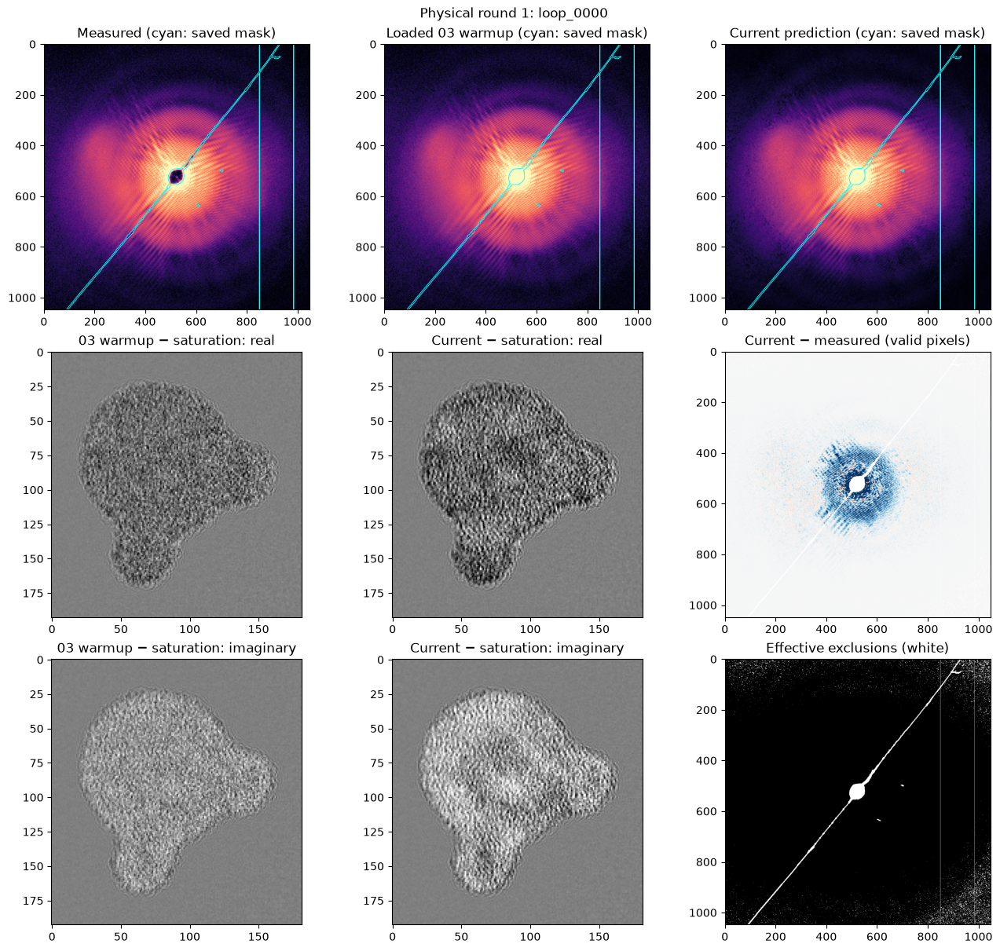

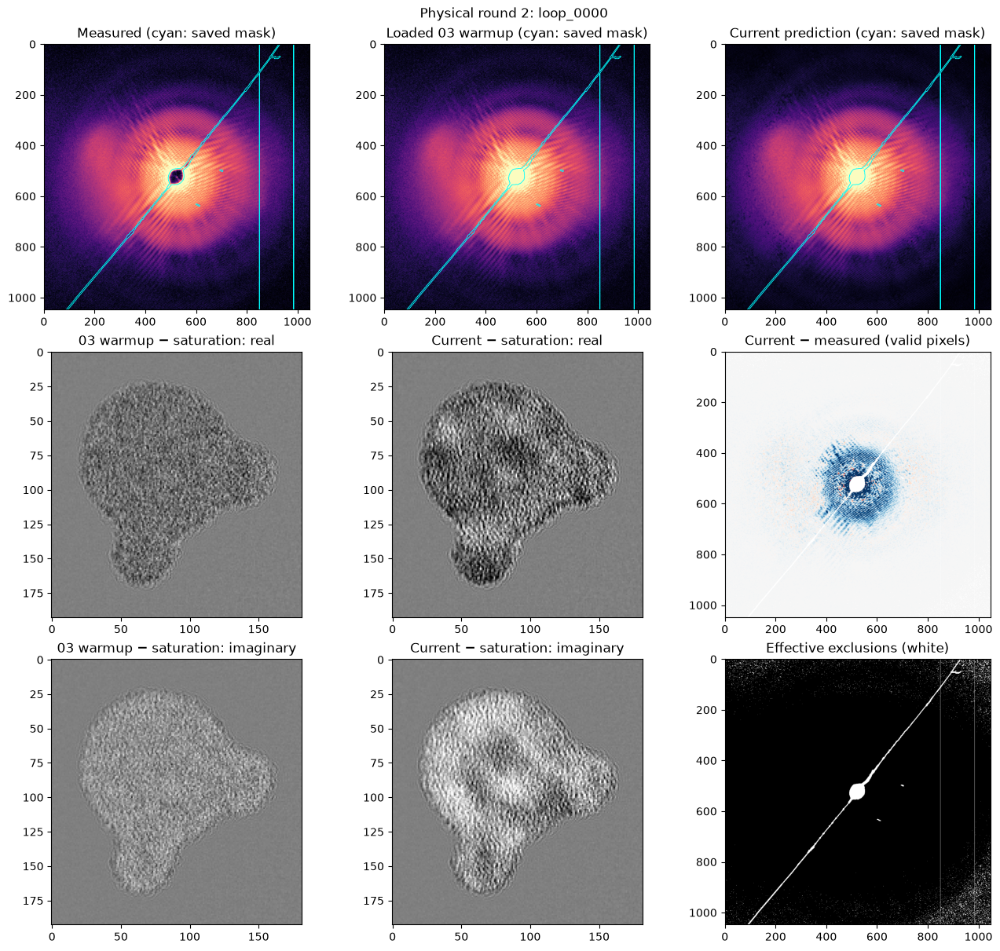

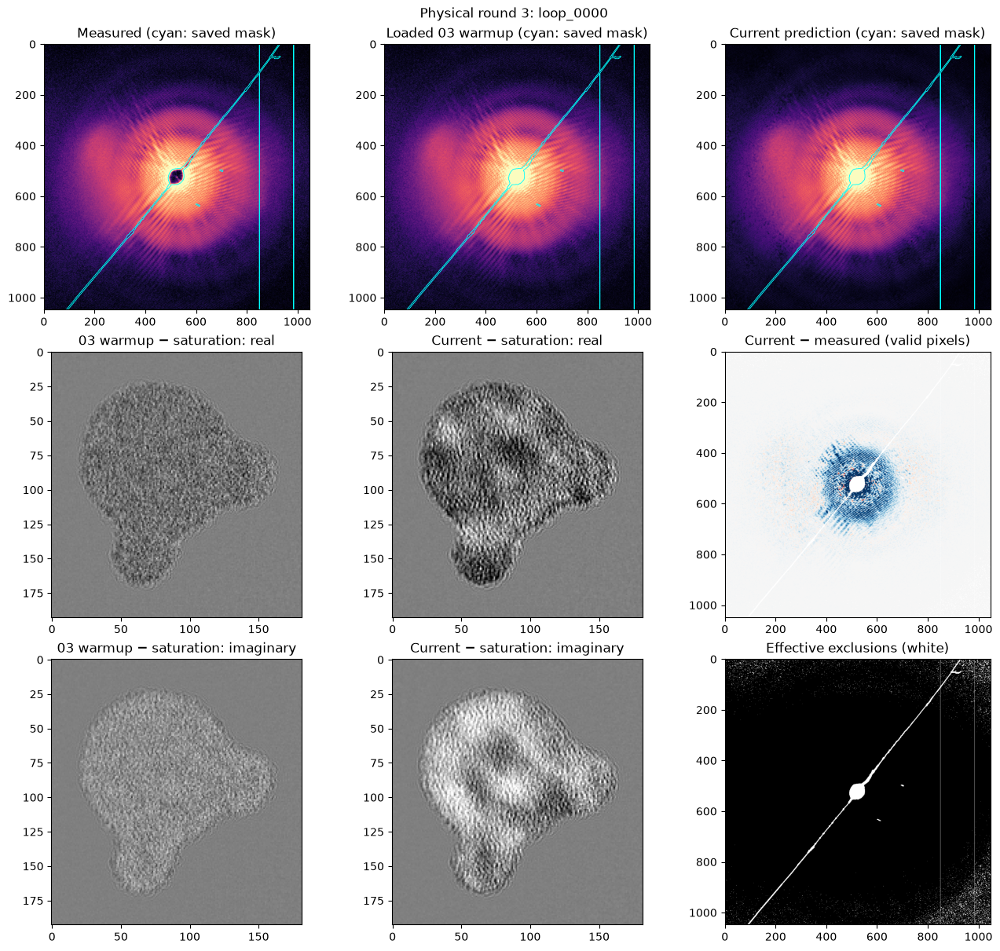

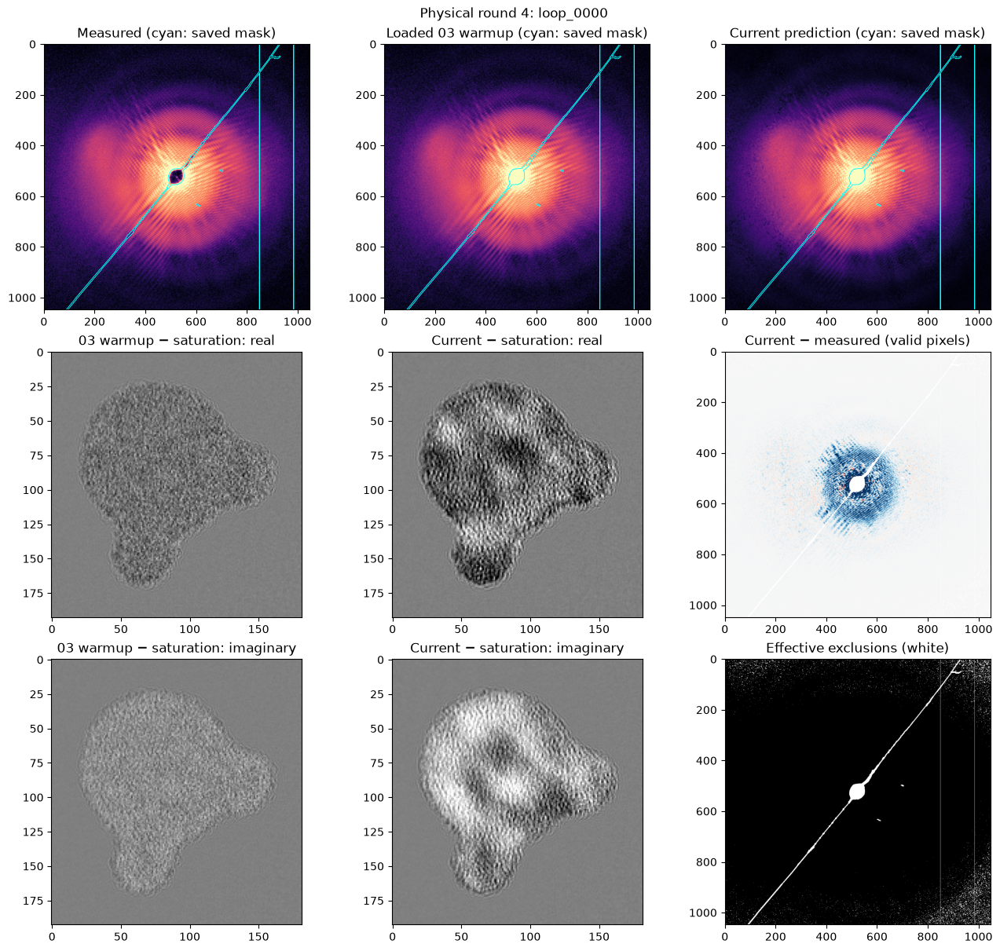

Verified: saved warmup fields and modal supports were preserved at entry.
Execution: {'requested_workers': 1, 'effective_workers': 1, 'max_concurrent_updates': 1, 'worker_threads_used': 1, 'summed_update_wall_seconds': 473.6488549219939}


In [7]:
# Fail before computation if an edit would silently restart warmup or change geometry.
if (recipe["warmup_Nit"] != 0 or recipe["warmup_reference_mode"] is not None
        or recipe["warmup_other_mode"] is not None):
    raise ValueError("03b starts from saved fields; keep every warmup schedule disabled")
if recipe["crop"] != 0 or recipe["binning"] != 1 or recipe["partial_coherence"]:
    raise ValueError("Keep the saved grid (crop=0, binning=1) and coherent continuation")
if recipe["projection_model"] != "physical_factorized" or recipe["projection_relaxation"] <= 0:
    raise ValueError("This notebook requires an enabled physical_factorized projection")
if recipe["projection_every"] != len(state_labels):
    raise ValueError("Use one physical projection per full state sweep: projection_every=len(state_labels)")
round_records = []

def on_projection(event):
    if event["stage"] != "physical_projection":
        return
    current = event["fields"]
    round_number = int(event["outer_round"])
    fit = event["components"]
    deviance = [poisson.poisson_deviance(
        poisson.predicted_intensity(modes_at(current, obs)), holograms[obs],
        effective_source_masks[obs]) for obs in range(len(state_labels))]
    record = dict(round=round_number, fit_residual_rms=float(fit["fit_residual_rms"]),
                  mean_deviance=float(np.mean(deviance)), deviance=deviance)
    round_records.append(record)
    (OUTPUT / "round_metrics.json").write_text(json.dumps(round_records, indent=2))
    comparison_figure(current, diagnostic_observation,
                      f"Physical round {round_number}: {state_labels[diagnostic_observation]}",
                      PNG_OUTPUT / f"round_{round_number:03d}.png", show=SHOW_ROUND_DIAGNOSTICS)
    if SAVE_ROUND_FIELDS:
        temporary = OUTPUT / f"round_{round_number:03d}.partial.h5"
        with h5py.File(temporary, "w") as h:
            h.create_dataset("fields", data=current, compression="gzip")
            h.attrs["field_domain"] = "centered Fourier"
            h.attrs["source_run"] = str(SOURCE_RUN)
            h.attrs["round"] = round_number
            save_tree(h.create_group("components"), fit)
        temporary.replace(OUTPUT / f"round_{round_number:03d}.h5")
    print(f"Saved round {round_number}: physical RMS={record['fit_residual_rms']:.6g}, "
          f"mean detector deviance={record['mean_deviance']:.6g}", flush=True)

with retrieval_progress(recipe, len(state_labels), kind="universal"):
    fields, loaded_warmup, components, bsmasks, errors = universal.universal_phase_retrieval_algorithm(
        holograms, effective_source_masks, support_used,
        state_labels=state_labels,
        energy_labels=[ENERGY_EV] * len(state_labels),
        polarization_coefficients=[1] * len(state_labels),
        illumination_labels=["beam0"] * len(state_labels),
        universal_recipe=recipe,
        start_fields=start_fields,
        phase_retrieval_kernel=unified.PhaseRtrv_core,
        progress_callback=on_projection,
    )
if not np.array_equal(loaded_warmup, start_fields):
    raise RuntimeError("Starting fields changed before the continuation; warmup was not skipped faithfully")
returned_supports = np.asarray(components["modal_supportmask_used"])
if returned_supports.ndim == 2:
    returned_supports = returned_supports[None]
if not np.array_equal(returned_supports, saved_modal_supports):
    raise RuntimeError("Solver modal supports differ from the saved 03 supports")
if list(components["state_names"]) != state_labels:
    raise RuntimeError("Physical state order differs from the loaded state order")
# Release the redundant solver snapshot; start_fields remains available for comparisons.
del loaded_warmup
print("Verified: saved warmup fields and modal supports were preserved at entry.")
print("Execution:", errors.get("execution_summary", {}))


## Save the numerical result before exporting plots

The components are from the last physical fit; the final fields may additionally satisfy the final detector/common-mode constraints. HDF5 contains both the initial and final fields so their difference is directly inspectable.

In [8]:
temporary = OUTPUT / "results.partial.h5"
with h5py.File(temporary, "w") as h:
    h.attrs.update(workflow="physical_continuation_from_03_warmup", field_domain="centered Fourier",
                   source_run=str(SOURCE_RUN), saturated_scan=SATURATED_SCAN, loop_scan=LOOP_SCAN,
                   energy_eV=ENERGY_EV, warmup_executed=False,
                   created_utc=datetime.now(timezone.utc).isoformat(),
                   recipe_json=json.dumps(recipe_metadata, default=json_value),
                   physical_components_note="Last physical fit, before final Fourier/common-mode constraints")
    for key, value in dict(fields=fields, warmup_fields=start_fields, measured=holograms,
                           mask_pixel=mask_pixel, effective_source_masks=effective_source_masks,
                           bsmasks=bsmasks, modal_supports=saved_modal_supports,
                           point_numbers=point_numbers, current_A=currents).items():
        h.create_dataset(key, data=value, compression="gzip" if np.ndim(value) else None)
    for key in ("material_mask", "material_thickness"):
        if recipe[key] is not None:
            h.create_dataset("input_" + key, data=recipe[key], compression="gzip")
    h.create_dataset("state_labels", data=np.asarray(state_labels, dtype=h5py.string_dtype()))
    h.create_dataset("source_paths", data=np.asarray([str(path) for path in source_paths], dtype=h5py.string_dtype()))
    save_tree(h.create_group("components"), components)
    save_tree(h.create_group("errors"), errors)
temporary.replace(OUTPUT / "results.h5")
print("Saved numerical results:", OUTPUT / "results.h5")


Exception ignored in: <function WeakValueDictionary.__init__.<locals>.remove at 0x767ebd22ea20>
Traceback (most recent call last):
  File "/home/riccardo/miniforge3/envs/myenv/lib/python3.13/weakref.py", line 105, in remove
    def remove(wr, selfref=ref(self), _atomic_removal=_remove_dead_weakref):
KeyboardInterrupt: 


Saved numerical results: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/processed/scans_2923_2924/physical_from_03/20261001_141231_561289/results.h5


## Final detector, reconstruction and physical-model diagnostics

All states get a detector comparison with cyan mask contours and a warmup/final difference comparison. Complex object reconstructions and primary-mode state-minus-saturation ROIs are written mode by mode to HDF5. Native PNGs use shared component limits across all states and both stages. The fitted magnetization uses the solver's shifted object convention; plots undo that shift.

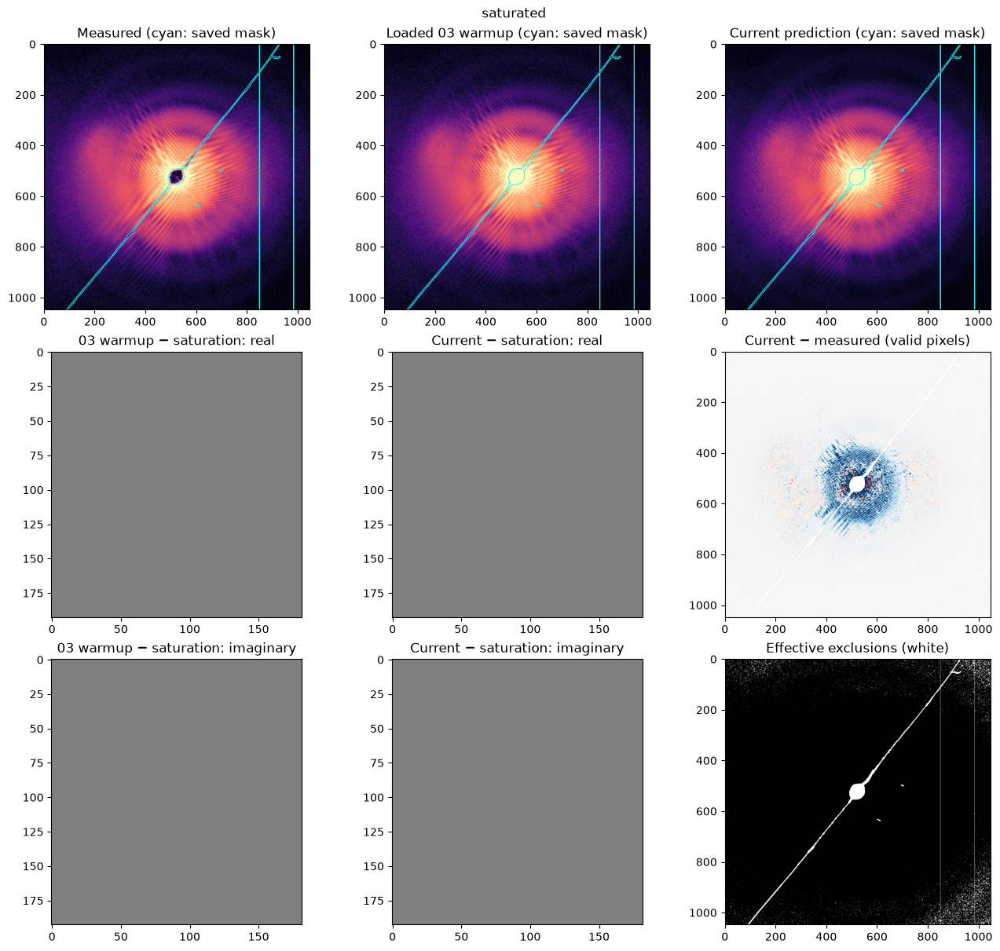

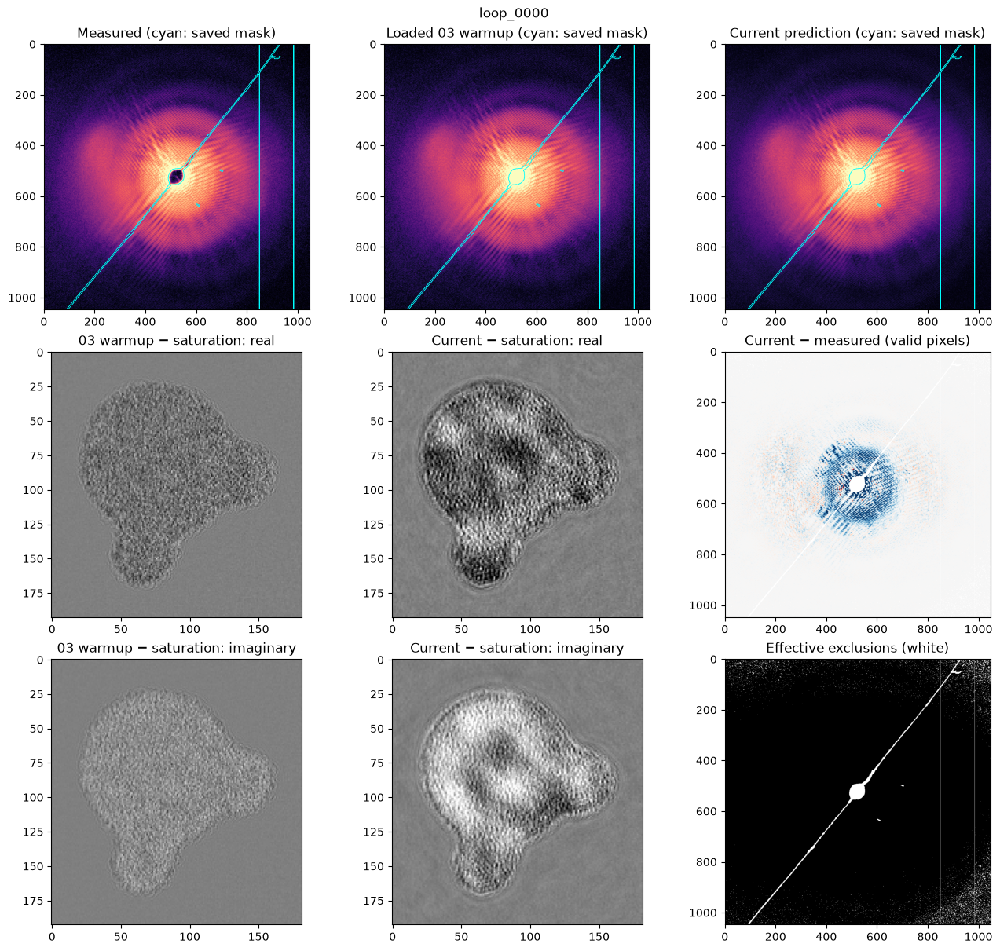

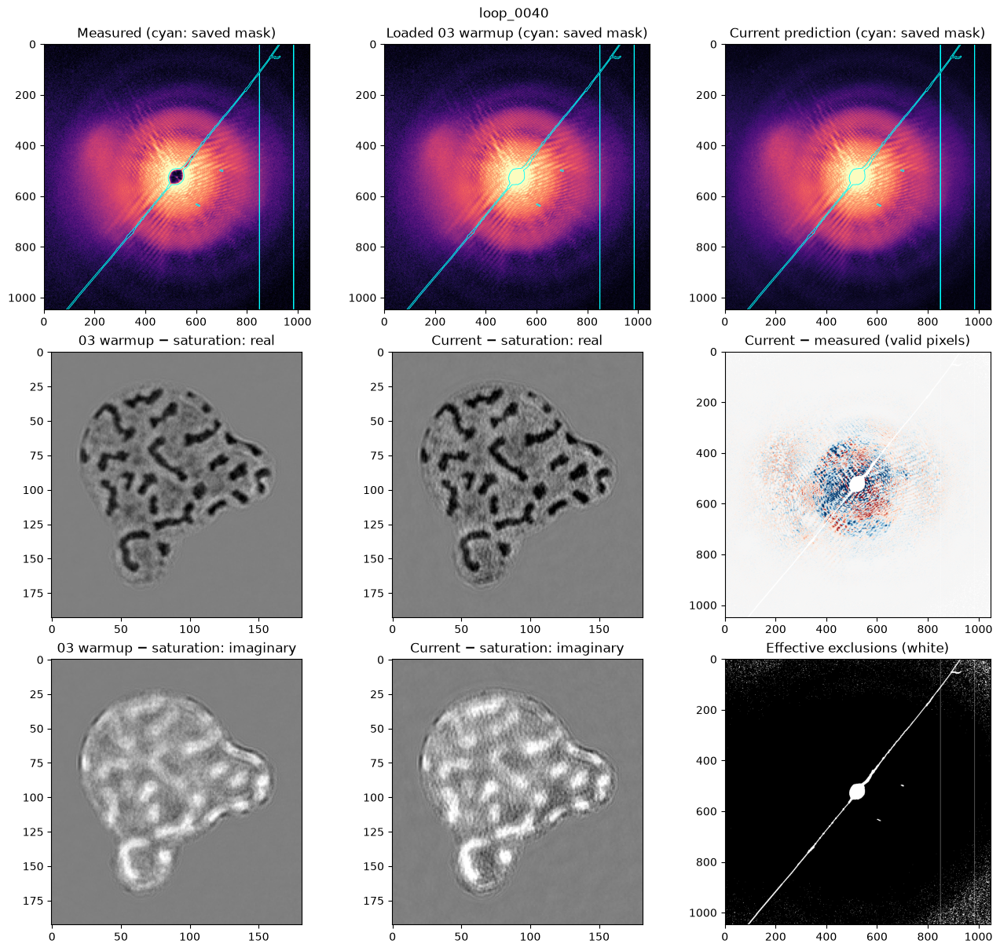

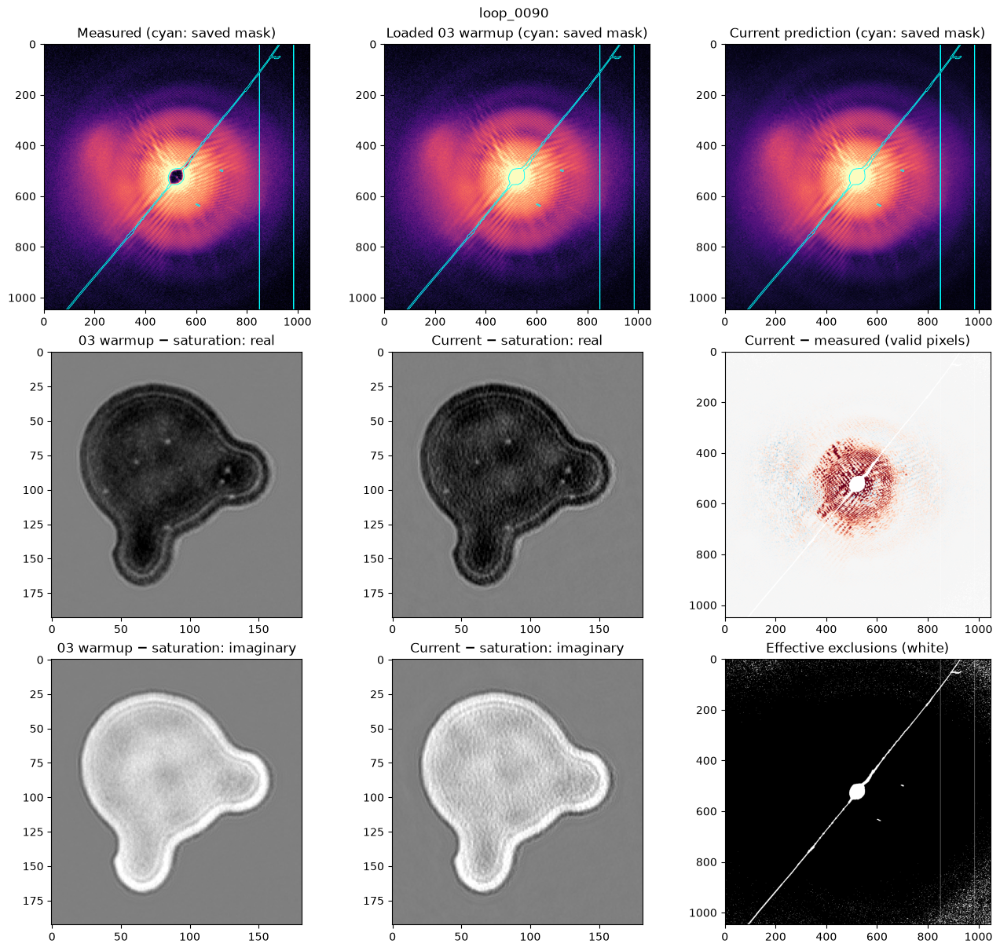

In [ ]:
stages = {"warmup": start_fields, "final": fields}
summary = []
for obs, label in enumerate(state_labels):
    scores = [poisson.poisson_deviance(poisson.predicted_intensity(modes_at(stack, obs)),
                                      holograms[obs], effective_source_masks[obs])
              for stack in stages.values()]
    summary.append(dict(label=label, point_number=int(point_numbers[obs]), current_A=float(currents[obs]),
                        warmup_deviance=scores[0], final_deviance=scores[1]))
    comparison_figure(fields, obs, label, PNG_OUTPUT / f"{label}_comparison.png",
                      show=(obs in {0, diagnostic_observation, len(state_labels) - 1}
                            or (obs + 1) % SHOW_EVERY == 0))
with (OUTPUT / "summary.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(summary[0]))
    writer.writeheader(); writer.writerows(summary)

# Stream object-space products into a separate file: one plane in memory at a time.
object_path = OUTPUT / "object_reconstructions.h5"
roi_shape = support_used[DIAGNOSTIC_ROI].shape
limits = {"amplitude": 1e-12, "real": 1e-12, "imaginary": 1e-12}
difference_limit = 1e-12
with h5py.File(object_path, "w") as h:
    h.attrs["display_settings_json"] = json.dumps(dict(
        focus_um=DISPLAY_PROP_UM, phase_rad=DISPLAY_PHASE_RAD, experimental_setup=DISPLAY_SETUP,
        roi=DIAGNOSTIC_ROI), default=json_value)
    h.create_dataset("state_labels", data=np.asarray(state_labels, dtype=h5py.string_dtype()))
    for stage, stack in stages.items():
        group = h.create_group(stage)
        reconstruction = group.create_dataset("reconstructions", shape=(len(state_labels), nmodes, ny, nx),
                                               dtype=np.complex128, compression="gzip", chunks=(1, 1, ny, nx))
        differences = group.create_dataset("differences", shape=(len(state_labels), *roi_shape),
                                           dtype=np.complex128, compression="gzip", chunks=(1, *roi_shape))
        reference_object = display_object(modes_at(stack, 0)[0])
        for obs in range(len(state_labels)):
            for mode, field in enumerate(modes_at(stack, obs)):
                obj = display_object(field)
                reconstruction[obs, mode] = obj
                for name, component in (("amplitude", np.abs), ("real", np.real), ("imaginary", np.imag)):
                    limits[name] = max(limits[name], float(np.percentile(np.abs(component(obj)), 99.5)))
                if mode == 0:
                    difference = (obj - reference_object)[DIAGNOSTIC_ROI]
                    differences[obs] = difference
                    difference_limit = max(difference_limit,
                                           float(np.percentile(np.abs(difference.real), 99)),
                                           float(np.percentile(np.abs(difference.imag), 99)))
(OUTPUT / "png_limits.json").write_text(json.dumps(dict(
    reconstruction=limits, difference_symmetric_limit=difference_limit,
    policy="shared across states, modes and warmup/final; percentile envelope"), indent=2))
if SAVE_NATIVE_PNGS:
    native = OUTPUT / "native_png"
    native.mkdir(exist_ok=True)
    with h5py.File(object_path, "r") as h:
        for stage in stages:
            for obs, label in enumerate(state_labels):
                for mode in range(nmodes):
                    obj = h[f"{stage}/reconstructions"][obs, mode]
                    for name, values, cmap, low, high in [
                        ("amplitude", np.abs(obj), "gray", 0, limits["amplitude"]),
                        ("phase", np.angle(obj), "twilight", -np.pi, np.pi),
                        ("real", obj.real, "RdBu_r", -limits["real"], limits["real"]),
                        ("imaginary", obj.imag, "RdBu_r", -limits["imaginary"], limits["imaginary"]),
                    ]:
                        plt.imsave(native / f"{stage}_{label}_mode_{mode:02d}_{name}.png",
                                   values, cmap=cmap, vmin=low, vmax=high, origin="upper")
                difference = h[f"{stage}/differences"][obs]
                for name, values in (("real", difference.real), ("imaginary", difference.imag)):
                    plt.imsave(native / f"{stage}_{label}_minus_saturated_{name}.png", values,
                               cmap="gray", vmin=-difference_limit, vmax=difference_limit, origin="upper")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for stage in ["warmup", "final"]:
    axes[0].plot(point_numbers, [row[f"{stage}_deviance"] for row in summary], ".-", label=stage)
axes[0].set(xlabel="Acquisition point (−1 = saturation)", ylabel="Mean detector deviance")
axes[0].legend()
axes[1].plot([row["round"] for row in round_records], [row["fit_residual_rms"] for row in round_records], "o-")
axes[1].set(xlabel="Physical round", ylabel="Physical fit RMS")
axes[2].plot([row["round"] for row in round_records], [row["mean_deviance"] for row in round_records], "o-")
axes[2].set(xlabel="Physical round", ylabel="Mean detector deviance after projection")
fig.savefig(PNG_OUTPUT / "convergence.png", dpi=150)
plt.show()

magnetization = np.asarray(components["magnetization"])
object_pixels = np.fft.fftshift(material_aperture) != 0
mean_magnetization = np.mean(magnetization[:, object_pixels], axis=1)
with (OUTPUT / "hysteresis.csv").open("w", newline="") as stream:
    writer = csv.writer(stream); writer.writerow(["point_number", "current_A", "mean_reduced_magnetization"])
    writer.writerows(zip(point_numbers, currents, mean_magnetization))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
axes[0].imshow(np.fft.ifftshift(magnetization[diagnostic_observation])[DIAGNOSTIC_ROI],
               cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_title(f"Last-fit magnetization: {state_labels[diagnostic_observation]}")
axes[1].imshow(np.fft.ifftshift(components["material_thickness"])[DIAGNOSTIC_ROI], cmap="gray")
axes[1].set_title("Relative material thickness")
axes[2].plot(currents[1:], mean_magnetization[1:], "o-")
axes[2].set(xlabel="Magnet current (A)", ylabel="Mean reduced magnetization")
fig.savefig(PNG_OUTPUT / "physical_model_and_hysteresis.png", dpi=150)
plt.show()
print("All results and diagnostics:", OUTPUT)
